# Spectral-spatial fingerprints: does each movement have its own energy per band *and* per electrode?

`motor_units_zoom.ipynb` looked at bands mostly on one electrode, or averaged over electrodes. Here we keep the
full **band × electrode** picture (5 bands × 16 channels = 80 numbers per instant) and ask:

1. Per stage: how does the band × electrode energy map change between movements? How much of that change is
   **spatial** (which electrodes), **spectral** (which bands), or a genuine **interaction** (a band that lights
   up only on some electrodes)?
2. Per finger: **movement-triggered maps** (the EMG analogue of an event-related spectral perturbation in
   EEG): the average band × electrode change when one finger flexes or extends, relative to rest.
3. Can we tell the movement from these features, and does the spectral dimension add anything over the spatial one?
4. What does the pretrained network "listen to"? Frequency response and spatial footprint of its 256 first-layer
   filters.

Data: mini dataset, **both hands pooled** (the paper states that electrode indices line up with the same anatomy
on both hands). Bands as in `motor_units_zoom.ipynb`.

## Setup

**Locally:** run `uv sync --extra cpu` in the repo root and pick the **semg2pose** kernel. The cell below does nothing.

**On Colab:** select *Runtime → Change runtime type → Runtime version 2026.07* (Python 3.12), optionally with a T4 GPU.
Run the cell below once; when it says so, do *Runtime → Restart session* and run the notebook from the top again.

In [1]:
# Colab only: clone semg2pose (with the emg2pose submodule) and install it. Locally this does nothing.
import os
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    if not (3, 10) <= sys.version_info[:2] < (3, 13):
        raise RuntimeError("Select Runtime > Change runtime type > Runtime version 2026.07 "
                           "(Python 3.12), then run this cell again.")
    REPO_DIR = Path("/content/semg2pose")
    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", "--recurse-submodules",
                        "https://github.com/eljoserass/semg2pose.git", str(REPO_DIR)], check=True)
    try:
        import semg2pose  # noqa: F401  (installed in a previous run + restart)
        print("semg2pose is installed, continue.")
    except ImportError:
        subprocess.run(["bash", str(REPO_DIR / "scripts" / "colab_setup.sh")], check=True,
                       env={**os.environ, "PYTHON": sys.executable})
        print("Installed. Now: Runtime > Restart session, then run the notebook from the top.")
else:
    print("Local kernel:", sys.executable)

Local kernel: /home/rodri/projects/emg2poseneuromatch/semg2pose/.venv/bin/python


In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from semg2pose.data import FS, JOINT_NAMES, download_mini_dataset, list_sessions, load_session
from semg2pose.signals import bandpass, rms_envelope
from semg2pose.model import download_checkpoints, load_pretrained

warnings.filterwarnings("ignore")
DATASET_DIR = download_mini_dataset()
plt.rcParams["figure.dpi"] = 100

BANDS = {"20-60": (20, 60), "60-120": (60, 120), "120-250": (120, 250),
         "250-500": (250, 500), "500-900": (500, 900)}
NB, NC = len(BANDS), 16
STEP = 100            # features at 20 Hz
FS_F = FS // STEP
LAG = int(0.06 * FS_F) or 1   # EMG leads movement by ~60 ms (emg_angle_correlation.ipynb)

Dataset already downloaded: /home/rodri/emg2pose_dataset_mini


## 1. Features: log band power per electrode, at 20 Hz

For every band: band-pass → moving RMS over 100 ms → log. Result per instant: an array (5 bands, 16 channels).
We also keep the joint angles and their velocities on the same 20 Hz grid.

In [3]:
sessions = list_sessions(DATASET_DIR)
data = []
for _, row in sessions.iterrows():
    emg, angles, ok, meta = load_session(row.path)
    idx = np.arange(0, len(emg), STEP)
    feats = np.stack([np.log(rms_envelope(bandpass(emg, lo, hi), window_s=0.1) + 1)[idx]
                      for lo, hi in BANDS.values()], axis=1)            # (T, 5, 16)
    ang = angles[idx]
    vel = signal.savgol_filter(angles, 401, 2, deriv=1, delta=1 / FS, axis=0)[idx]  # rad/s, 200 ms local fit
    good = ~np.convolve(~ok[idx], np.ones(5), mode="same").astype(bool)
    data.append({"stage": row.stage, "side": row.side, "feats": feats, "ang": ang, "vel": vel, "ok": good,
                 "rms": emg.std()})
print(f"{len(data)} recordings; feature array per instant: {data[0]['feats'].shape[1:]} (bands, channels)")

30 recordings; feature array per instant: (5, 16) (bands, channels)


## 2. One band × electrode map per stage

For each stage: the mean log power of every (band, channel) cell over valid frames, averaged over both hands.
`unconstrained` is left out (its EMG is at the noise floor). Then we subtract the average over stages, so each
map shows **how that stage differs from a typical stage**.

In [4]:
stage_maps = {}
for st in sorted({d["stage"] for d in data} - {"unconstrained"}):
    stage_maps[st] = np.mean([d["feats"][d["ok"]].mean(0) for d in data if d["stage"] == st], axis=0)
names = list(stage_maps)
L = np.stack([stage_maps[s] for s in names])          # (stages, bands, channels)
D = L - L.mean(0)                                     # deviation from the average stage

# Decompose each stage's deviation:  D = level + spatial + spectral + interaction
level = D.mean(axis=(1, 2), keepdims=True)            # whole map brighter/darker (overall effort)
spatial = D.mean(axis=1, keepdims=True) - level       # same change in every band, varies by channel
spectral = D.mean(axis=2, keepdims=True) - level      # same change on every channel, varies by band
inter = D - level - spatial - spectral                # band x channel specific
parts = {"overall level": level, "spatial (which electrodes)": spatial,
         "spectral (which bands)": spectral, "band x electrode interaction": inter}
total = (D ** 2).sum()
share = pd.Series({k: (np.broadcast_to(v, D.shape) ** 2).sum() / total * 100 for k, v in parts.items()},
                  name="% of between-stage variance")
share.round(1).to_frame()

,% of between-stage variance
overall level,66.0
spatial (which electrodes),21.6
spectral (which bands),9.0
band x electrode interaction,3.4


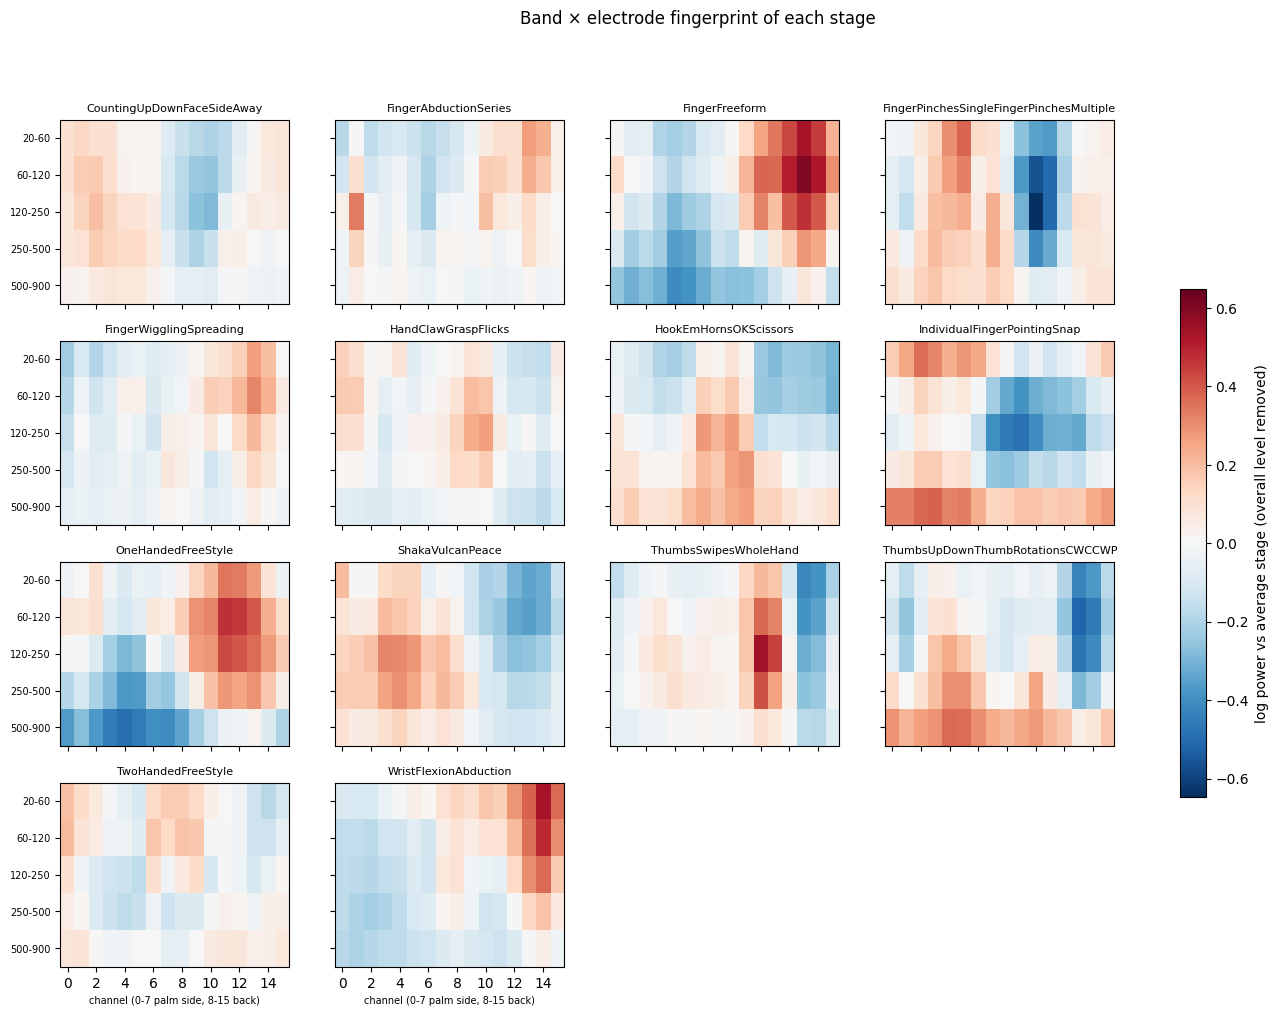

In [5]:
nrow, ncol = 4, 4
fig, axs = plt.subplots(nrow, ncol, figsize=(17, 11), sharex=True, sharey=True)
pattern = D - level                                   # remove overall level: show the *pattern*
lim = np.abs(pattern).max()
for ax, st, M in zip(axs.ravel(), names, pattern):
    im = ax.imshow(M, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    ax.set_title(st, fontsize=8)
for ax in axs.ravel()[len(names):]:
    ax.axis("off")
for ax in axs[:, 0]:
    ax.set_yticks(range(NB), list(BANDS), fontsize=7)
for ax in axs[-1]:
    ax.set_xticks(range(0, 16, 2)); ax.set_xlabel("channel (0-7 palm side, 8-15 back)", fontsize=7)
fig.colorbar(im, ax=axs, shrink=0.6, label="log power vs average stage (overall level removed)")
fig.suptitle("Band × electrode fingerprint of each stage")
plt.show()

**Reading it.** Many maps show **vertical stripes** (a group of electrodes up or down in all bands): that is the
spatial term, *which muscles* the movement uses. Rows changing on their own (e.g. the whole 500-900 Hz row of
`IndividualFingerPointingSnap`) are the spectral term, and tilted patterns (low bands up on one side, high bands
down on the other, as in `FingerFreeform`) the interaction. The table above quantifies it.

## 3. Movement-triggered maps: what does each finger "look like" on the band?

Neuroscience analogue: an **event-related spectral perturbation** (ERSP) in EEG, or a **tuning curve** in motor
cortex: average the activity around a type of event and compare with baseline.

- **Events**: for each 50 ms frame, the flexion velocity of each finger (mean of its FE joint velocities; thumb:
  CMC, MCP, IP). A frame is "*finger f flexing*" (or extending) if f moves faster than 1 rad/s **and** at least 1.5×
  faster than any other finger (to favour individuated movements).
- **Baseline**: frames where every finger moves slower than 0.15 rad/s.
- **EMG taken 60 ms earlier** than the movement (electromechanical delay).
- **Map** = mean log power during the event − mean during baseline, per (band, channel).

In [6]:
FINGERS = {"thumb": ["THUMB_CMC_FE", "THUMB_MCP_FE", "THUMB_IP_FE"]}
for f in ["INDEX", "MIDDLE", "RING", "PINKY"]:
    FINGERS[f.lower()] = [f"{f}_MCP_FE", f"{f}_PIP_FE", f"{f}_DIP_FE"]
FIDX = {f: [JOINT_NAMES.index(n) for n in js] for f, js in FINGERS.items()}


def finger_labels(d, thr=1.0, dominance=1.5, rest_thr=0.15):
    fv = np.stack([d["vel"][:, FIDX[f]].mean(1) for f in FINGERS], axis=1)  # (T, 5) signed flexion velocity
    sp = np.abs(fv)
    order = np.sort(sp, axis=1)
    top = sp.argmax(1)
    moving = (order[:, -1] > thr) & (order[:, -1] > dominance * order[:, -2])
    lab = np.full(len(fv), "", dtype=object)
    names_f = list(FINGERS)
    for i in np.where(moving)[0]:
        lab[i] = f"{names_f[top[i]]} {'flex' if fv[i, top[i]] > 0 else 'extend'}"
    lab[(order[:, -1] < rest_thr)] = "rest"
    return lab


events, feats_lagged = [], []
for d in data:
    lab = finger_labels(d)
    F_lag = np.vstack([np.repeat(d["feats"][:1], LAG, axis=0), d["feats"][:-LAG]])  # EMG at t - 60 ms
    keep = d["ok"] & (lab != "")
    events.append(lab[keep]); feats_lagged.append(F_lag[keep])
events = np.concatenate(events)
feats_lagged = np.concatenate(feats_lagged)
counts = pd.Series(events).value_counts()
print("frames per event type (20 Hz):"); print(counts.to_string())

frames per event type (20 Hz):
rest             3094
thumb extend      912
thumb flex        896
index extend      894
index flex        800
pinky extend      641
pinky flex        577
middle extend     575
middle flex       475
ring extend       224
ring flex         157


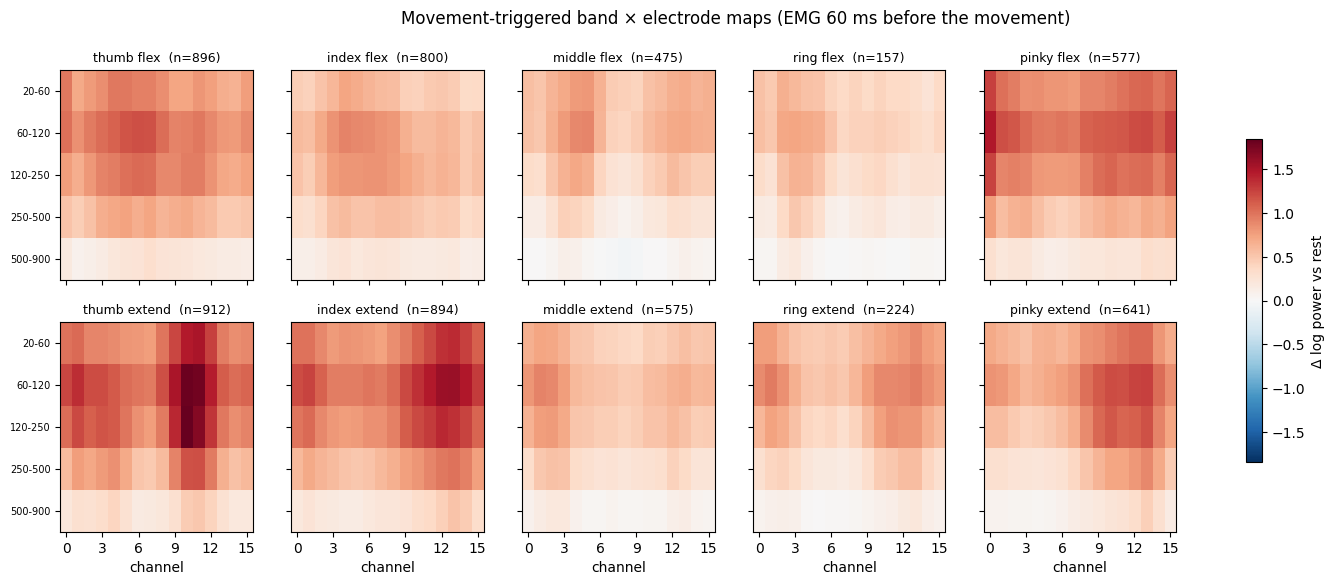

In [7]:
base = feats_lagged[events == "rest"].mean(0)
ev_types = [f"{f} {m}" for f in FINGERS for m in ["flex", "extend"]]
ev_maps = {e: feats_lagged[events == e].mean(0) - base for e in ev_types if (events == e).sum() >= 20}

fig, axs = plt.subplots(2, 5, figsize=(18, 6), sharex=True, sharey=True)
lim = max(np.abs(m).max() for m in ev_maps.values())
for j, f in enumerate(FINGERS):
    for i, mode in enumerate(["flex", "extend"]):
        ax = axs[i, j]
        e = f"{f} {mode}"
        if e in ev_maps:
            im = ax.imshow(ev_maps[e], cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
            ax.set_title(f"{e}  (n={counts.get(e, 0)})", fontsize=9)
        else:
            ax.set_title(f"{e}: too few events", fontsize=9)
        ax.set_yticks(range(NB), list(BANDS), fontsize=7)
        ax.set_xticks(range(0, 16, 3))
for ax in axs[-1]:
    ax.set_xlabel("channel")
fig.colorbar(im, ax=axs, shrink=0.7, label="Δ log power vs rest")
fig.suptitle("Movement-triggered band × electrode maps (EMG 60 ms before the movement)")
plt.show()

The same maps as **topographies around the wrist** (one band, 120-250 Hz, the most local one according to
`motor_units_zoom.ipynb` 8.4), normalised per event so the *shape* can be compared:

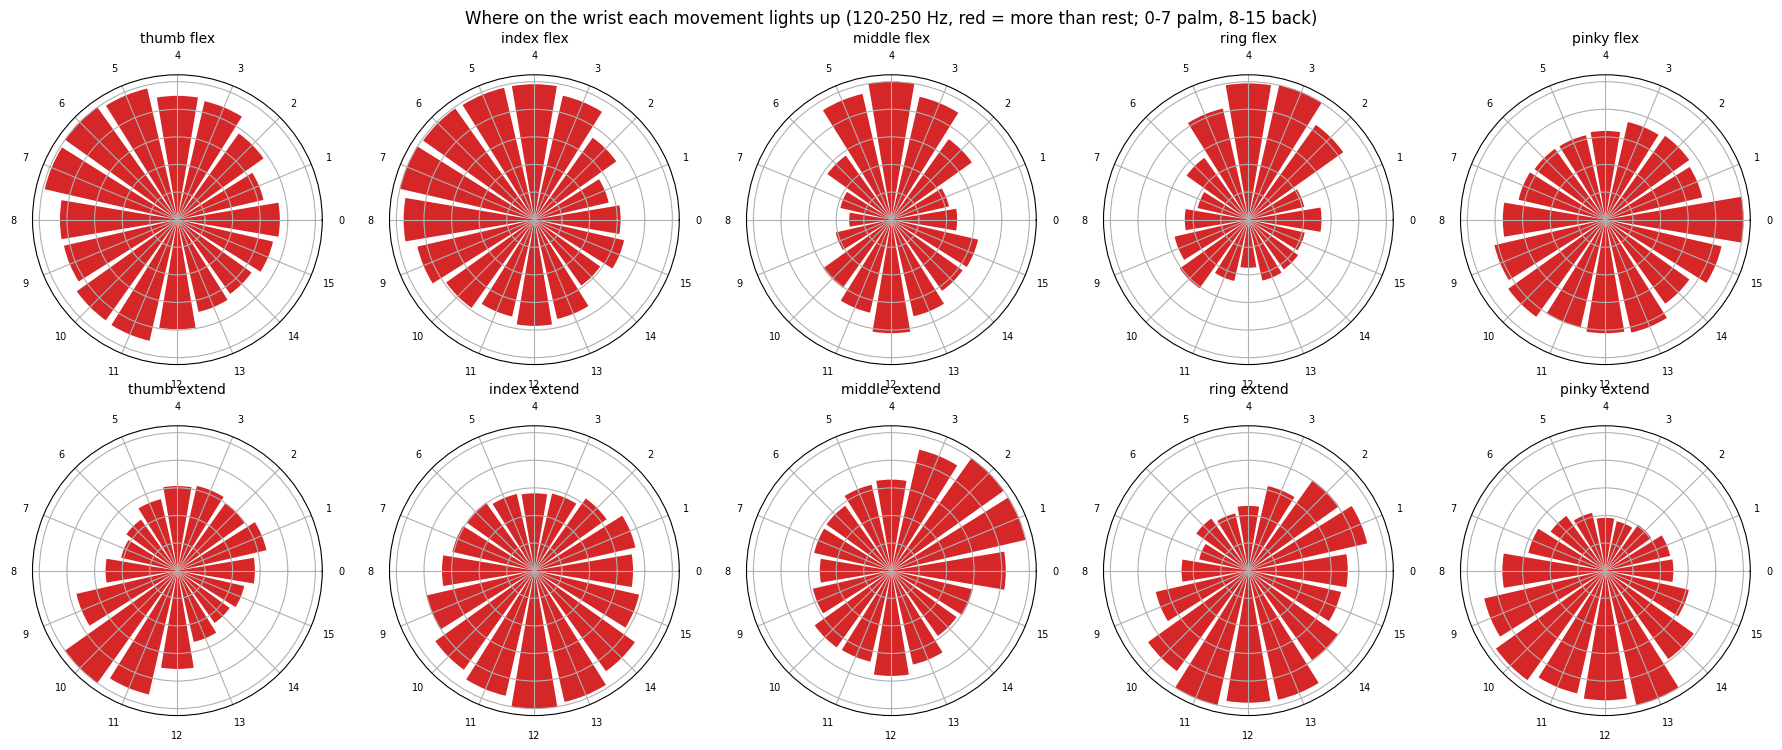

In [8]:
ang_c = 2 * np.pi * np.arange(16) / 16
b = list(BANDS).index("120-250")
fig, axs = plt.subplots(2, 5, figsize=(18, 7.5), subplot_kw={"projection": "polar"})
for j, f in enumerate(FINGERS):
    for i, mode in enumerate(["flex", "extend"]):
        ax = axs[i, j]
        e = f"{f} {mode}"
        if e not in ev_maps:
            ax.set_title(f"{e}: n/a", fontsize=9); continue
        v = ev_maps[e][b]
        v = v / np.abs(v).max()
        ax.bar(ang_c, np.abs(v), width=2 * np.pi / 16 * 0.85, color=np.where(v > 0, "tab:red", "tab:blue"))
        ax.set_xticks(ang_c, [str(c) for c in range(16)], fontsize=7)
        ax.set_yticklabels([])
        ax.set_title(e, fontsize=10)
fig.suptitle("Where on the wrist each movement lights up (120-250 Hz, red = more than rest; 0-7 palm, 8-15 back)")
plt.tight_layout(); plt.show()

**How similar are the fingerprints?** Correlation between the event maps (80 numbers each). If each finger had
its own fingerprint, the off-diagonal would be low.

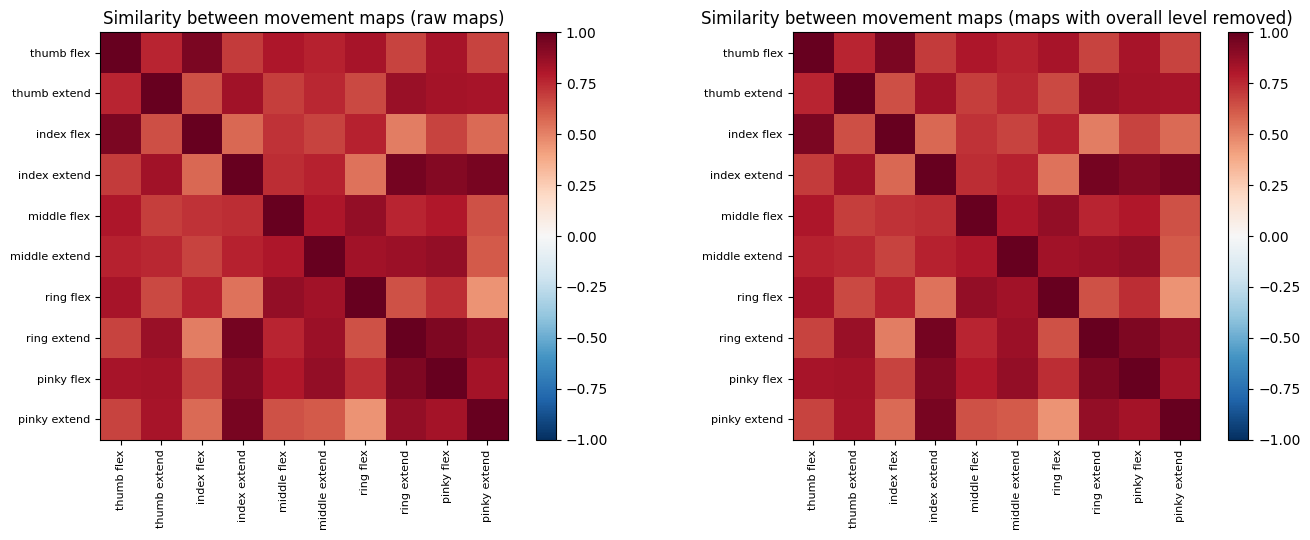

In [9]:
keys = list(ev_maps)
M = np.array([ev_maps[k].ravel() for k in keys])
C_ev = np.corrcoef(M)
M_shape = np.array([(ev_maps[k] - ev_maps[k].mean()).ravel() for k in keys])   # remove overall level
C_shape = np.corrcoef(M_shape)
fig, axs = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, C, title in [(axs[0], C_ev, "raw maps"), (axs[1], C_shape, "maps with overall level removed")]:
    im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(keys)), keys, rotation=90, fontsize=8)
    ax.set_yticks(range(len(keys)), keys, fontsize=8)
    ax.set_title(f"Similarity between movement maps ({title})")
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

## 4. Can we tell the movement from the features? Does the spectral axis help?

Two classification problems, each with five feature sets that isolate "where" from "which band":

| feature set | size | what it contains |
|---|---|---|
| spatial only | 16 | broadband-like: mean over bands of the log power, per channel |
| spectral only | 5 | mean over channels, per band |
| spectral shape per electrode | 80 | each channel's band profile with its own mean removed (no "how much", only "which bands") |
| spatial × spectral | 80 | all 80 cells |
| spatial + time context (control) | 80 | the 16 spatial features now and 100, 200, 300, 400 ms earlier |

The control matters: 80 features almost always beat 16, whatever they are (see `motor_units_zoom.ipynb` §9). The
fair comparison for the band axis is against the same number of features spent on temporal context.

Classifier: logistic regression (linear), standardised features, **blocked 5-fold CV** (each recording cut in 5
contiguous blocks, so test frames are never neighbours of training frames). Metric: balanced accuracy.

- **Problem A: which stage** (14 classes; chance 7 %): a coarse "movement repertoire" label.
- **Problem B: which finger moves, and which way** (the event labels of section 3 + rest).

**A confound in problem A.** Each stage is a separate recording, made at a different time of the session. EMG
properties drift over a session (electrode-skin contact, sweat, fatigue), so a classifier can partly recognise
*the recording* instead of *the movement*, and spectral shape is exactly the kind of feature that drifts. Problem B
is cleaner: its classes occur in many recordings, and we additionally **subtract each recording's mean feature
vector** before classifying, so recording-level offsets cannot be used.

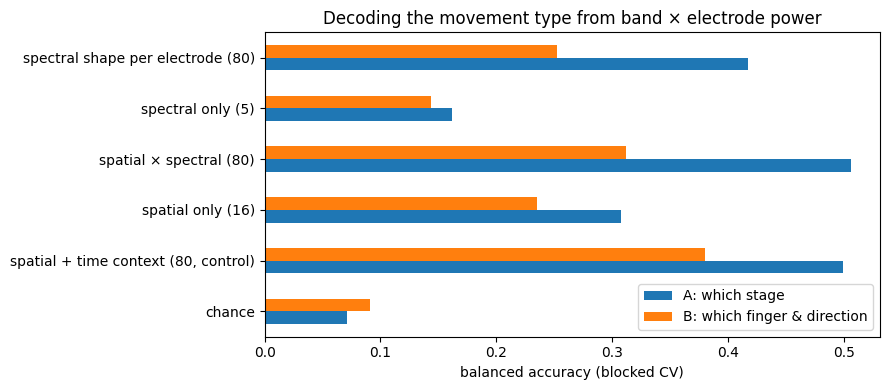

classes in B: ['index extend', 'index flex', 'middle extend', 'middle flex', 'pinky extend', 'pinky flex', 'rest', 'ring extend', 'ring flex', 'thumb extend', 'thumb flex']


,A: which stage,B: which finger & direction
chance,0.071,0.091
"spatial + time context (80, control)",0.499,0.380
spatial only (16),0.308,0.235
spatial × spectral (80),0.506,0.312
spectral only (5),0.162,0.143
spectral shape per electrode (80),0.417,0.252


In [10]:
def with_lags(X, lags):
    return np.hstack([X if r == 0 else np.vstack([np.repeat(X[:1], r, axis=0), X[:-r]]) for r in lags])


def feature_sets(F, BBL):  # F: (N, 5, 16) band x channel; BBL: (N, 80) spatial features at 5 time lags
    return {"spatial only (16)": F.mean(1),
            "spectral only (5)": F.mean(2),
            "spectral shape per electrode (80)": (F - F.mean(1, keepdims=True)).reshape(len(F), -1),
            "spatial × spectral (80)": F.reshape(len(F), -1),
            "spatial + time context (80, control)": BBL}


def blocked_cv(Xf, y, folds):
    pred = np.empty_like(y)
    for k in range(5):
        tr, te = folds != k, folds == k
        clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=1.0))
        clf.fit(Xf[tr], y[tr])
        pred[te] = clf.predict(Xf[te])
    return balanced_accuracy_score(y, pred), pred


CONTEXT = [0, 2, 4, 6, 8]  # 0-400 ms at 20 Hz

# Problem A: stage
FA, BA, yA, fA = [], [], [], []
for d in data:
    if d["stage"] == "unconstrained":
        continue
    sel = np.arange(len(d["ok"]))
    FA.append(d["feats"]); BA.append(with_lags(d["feats"].mean(1), CONTEXT))
    yA.append(np.full(len(sel), d["stage"])); fA.append(sel * 5 // len(sel))
FA, BA, yA, fA = np.concatenate(FA), np.concatenate(BA), np.concatenate(yA), np.concatenate(fA)

# Problem B: finger events (fold = block inside its own recording), recording mean subtracted
FB, BB, yB, fB = [], [], [], []
for d in data:
    lab = finger_labels(d)
    F0 = d["feats"] - d["feats"][d["ok"]].mean(0)              # remove the recording's mean
    F_lag = np.vstack([np.repeat(F0[:1], LAG, axis=0), F0[:-LAG]])
    blocks = np.arange(len(lab)) * 5 // len(lab)
    keep = d["ok"] & (lab != "")
    FB.append(F_lag[keep]); BB.append(with_lags(F_lag.mean(1), CONTEXT)[keep])
    yB.append(lab[keep]); fB.append(blocks[keep])
FB, BB, yB, fB = np.concatenate(FB), np.concatenate(BB), np.concatenate(yB).astype(str), np.concatenate(fB)
common = pd.Series(yB).value_counts()
common = common[common >= 40].index
mB = np.isin(yB, common)
FB, BB, yB, fB = FB[mB], BB[mB], yB[mB], fB[mB]

acc = {}
preds_cls = {}
for problem, (Fp, Bp, yp, fp) in {"A: which stage": (FA, BA, yA, fA),
                                  "B: which finger & direction": (FB, BB, yB, fB)}.items():
    for name, Xf in feature_sets(Fp, Bp).items():
        a, p = blocked_cv(Xf, yp, fp)
        acc[(problem, name)] = a
        preds_cls[(problem, name)] = p
    acc[(problem, "chance")] = 1 / len(np.unique(yp))
acc = pd.Series(acc).unstack(0)
ax = acc.plot.barh(figsize=(9, 4))
ax.set_xlabel("balanced accuracy (blocked CV)"); ax.set_title("Decoding the movement type from band × electrode power")
plt.tight_layout(); plt.show()
print("classes in B:", sorted(np.unique(yB)))
acc.round(3)

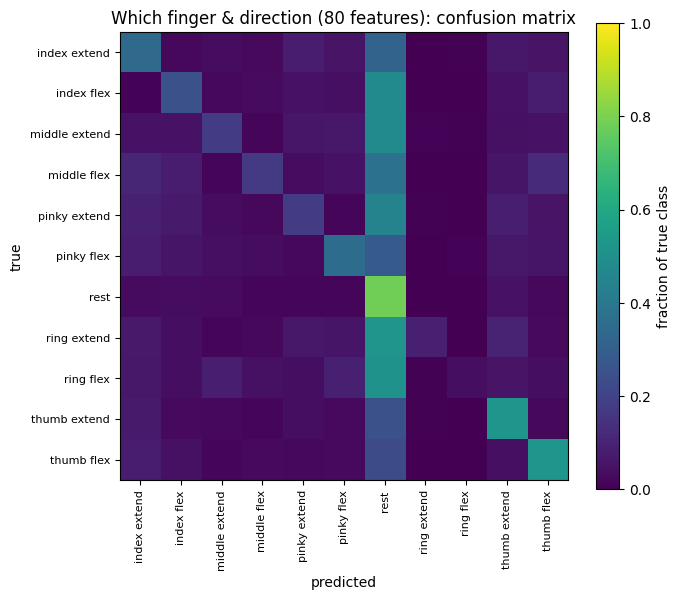

In [11]:
labels_B = sorted(np.unique(yB))
cm = confusion_matrix(yB, preds_cls[("B: which finger & direction", "spatial × spectral (80)")], labels=labels_B,
                      normalize="true")
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(labels_B)), labels_B, rotation=90, fontsize=8)
ax.set_yticks(range(len(labels_B)), labels_B, fontsize=8)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.colorbar(im, ax=ax, label="fraction of true class")
ax.set_title("Which finger & direction (80 features): confusion matrix")
plt.tight_layout(); plt.show()

## 5. What does the pretrained network listen to?

vemg2pose's first layer has **256 filters, each 16 channels × 11 samples (5.5 ms)**. Every filter is a joint
spatial + temporal (≈ spectral) pattern learned only to predict pose. We decompose each filter with an SVD into its
best **spatial pattern** (16 weights, one per electrode) × **temporal kernel** (11 taps), check how well that
rank-1 approximation holds, and look at the frequency response of the temporal kernels.

Caveat: 11 taps at 2 kHz cannot make narrow filters (resolution ≈ 2000/11 ≈ 180 Hz); this layer can only say
"low", "mid" or "high". Finer frequency selectivity, if any, is built by later layers.

Checkpoints already downloaded: /home/rodri/emg2pose_model_checkpoints


Lightning automatically upgraded your loaded checkpoint from v1.8.6 to v2.2.2. To apply the upgrade to your files permanently, run `python -m pytorch_lightning.utilities.upgrade_checkpoint ../../../../emg2pose_model_checkpoints/tracking_vemg2pose.ckpt`


first-layer weights: (256, 16, 11) (filters, channels, taps)


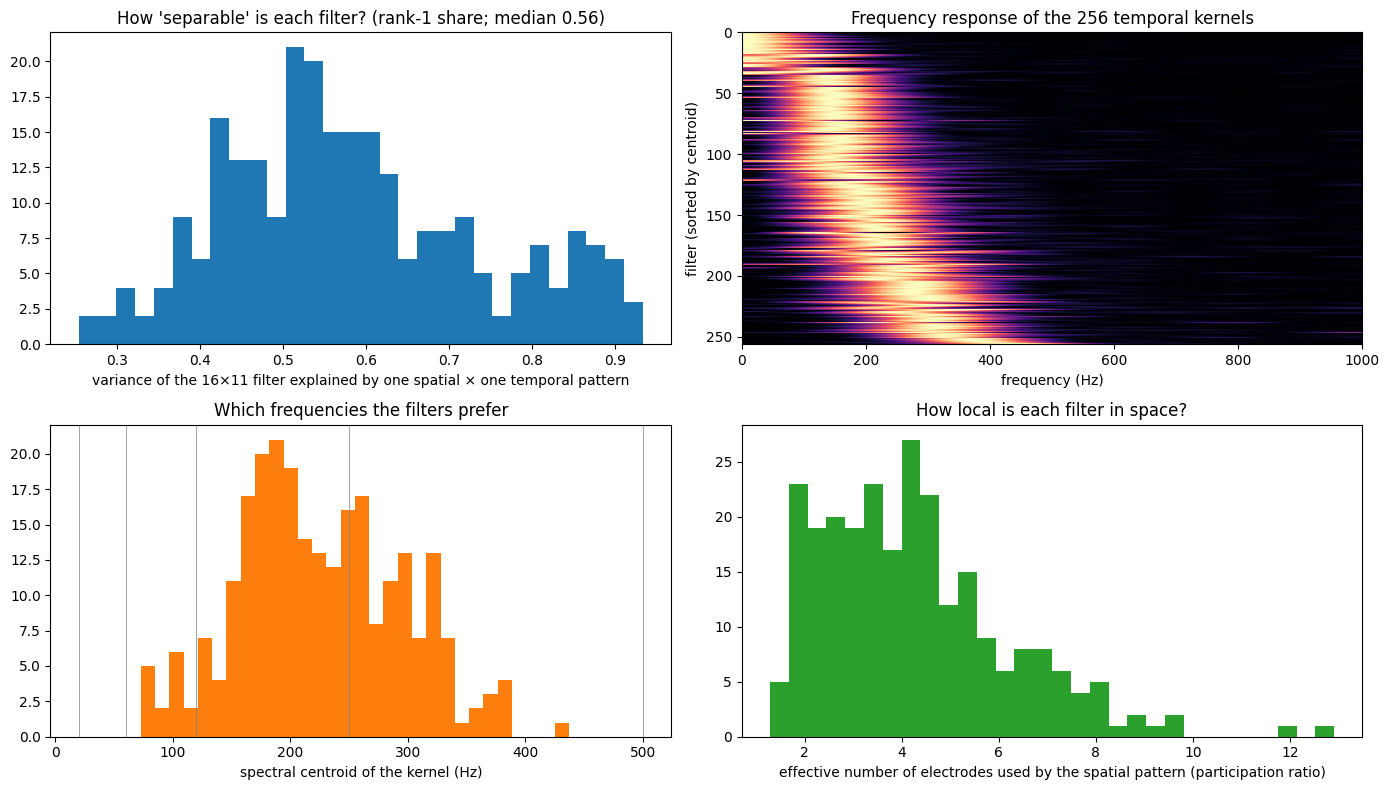

centroid: median 218 Hz (IQR 174-277); electrodes per filter: median 4.0


In [12]:
module = load_pretrained("tracking_vemg2pose", download_checkpoints())
Wt = module.model.network.layers[0].conv[0].weight.detach().numpy()   # (256, 16, 11)
print("first-layer weights:", Wt.shape, "(filters, channels, taps)")

spatial_pat, temporal_k, rank1 = [], [], []
for w in Wt:
    U, s, Vt = np.linalg.svd(w, full_matrices=False)
    spatial_pat.append(U[:, 0] * s[0]); temporal_k.append(Vt[0]); rank1.append(s[0] ** 2 / (s ** 2).sum())
spatial_pat, temporal_k, rank1 = np.array(spatial_pat), np.array(temporal_k), np.array(rank1)

NFFT = 256
freqs = np.fft.rfftfreq(NFFT, 1 / FS)
H = np.abs(np.fft.rfft(temporal_k, NFFT, axis=1)) ** 2
H_norm = H / H.max(1, keepdims=True)
centroid = (H * freqs).sum(1) / H.sum(1)
peak = freqs[H.argmax(1)]
n_ch = (spatial_pat ** 2).sum(1) ** 2 / (spatial_pat ** 4).sum(1)   # participation ratio over channels

fig, axs = plt.subplots(2, 2, figsize=(14, 8))
axs[0, 0].hist(rank1, bins=30)
axs[0, 0].set_title(f"How 'separable' is each filter? (rank-1 share; median {np.median(rank1):.2f})")
axs[0, 0].set_xlabel("variance of the 16×11 filter explained by one spatial × one temporal pattern")
order_f = np.argsort(centroid)
axs[0, 1].imshow(H_norm[order_f], aspect="auto", extent=[0, FS / 2, 256, 0], cmap="magma")
axs[0, 1].set_xlabel("frequency (Hz)"); axs[0, 1].set_ylabel("filter (sorted by centroid)")
axs[0, 1].set_title("Frequency response of the 256 temporal kernels")
axs[1, 0].hist(centroid, bins=30, color="tab:orange")
for lo, hi in BANDS.values():
    axs[1, 0].axvline(lo, color="gray", lw=0.5)
axs[1, 0].set_xlabel("spectral centroid of the kernel (Hz)"); axs[1, 0].set_title("Which frequencies the filters prefer")
axs[1, 1].hist(n_ch, bins=30, color="tab:green")
axs[1, 1].set_xlabel("effective number of electrodes used by the spatial pattern (participation ratio)")
axs[1, 1].set_title("How local is each filter in space?")
plt.tight_layout(); plt.show()
print(f"centroid: median {np.median(centroid):.0f} Hz (IQR {np.percentile(centroid, 25):.0f}-{np.percentile(centroid, 75):.0f});"
      f" electrodes per filter: median {np.median(n_ch):.1f}")

Spatial side: which electrodes carry the most first-layer weight (summed over filters), and a few example
filters as 16 × 11 images.

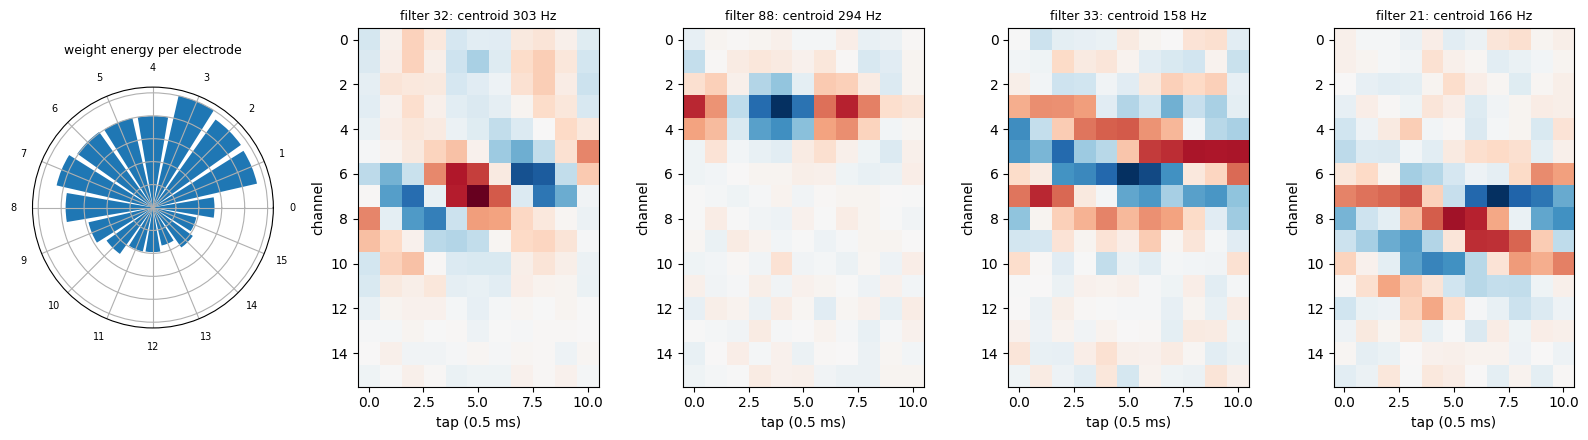

In [13]:
energy = (Wt ** 2).sum(axis=(0, 2))
fig = plt.figure(figsize=(16, 4.5))
ax = fig.add_subplot(1, 5, 1, projection="polar")
ax.bar(ang_c, energy / energy.max(), width=2 * np.pi / 16 * 0.85)
ax.set_xticks(ang_c, [str(c) for c in range(16)], fontsize=7); ax.set_yticklabels([])
ax.set_title("weight energy per electrode", fontsize=9)
strongest = np.argsort((Wt ** 2).sum(axis=(1, 2)))[::-1][:4]
for i, fidx in enumerate(strongest):
    ax = fig.add_subplot(1, 5, i + 2)
    lim = np.abs(Wt[fidx]).max()
    ax.imshow(Wt[fidx], cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    ax.set_title(f"filter {fidx}: centroid {centroid[fidx]:.0f} Hz", fontsize=9)
    ax.set_xlabel("tap (0.5 ms)"); ax.set_ylabel("channel")
plt.tight_layout(); plt.show()

## 6. Summary

(Numbers from this run; interpretation in the cell below.)

In [14]:
print("Between-stage variance of the band x electrode maps:")
print(share.round(1).to_string())
print("\nBalanced accuracy (blocked CV):")
print(acc.round(3).to_string())
print(f"\nFirst-layer filters: rank-1 share median {np.median(rank1):.2f}, spectral centroid median {np.median(centroid):.0f} Hz,"
      f" effective electrodes per filter median {np.median(n_ch):.1f}")

Between-stage variance of the band x electrode maps:
overall level                   66.0
spatial (which electrodes)      21.6
spectral (which bands)           9.0
band x electrode interaction     3.4

Balanced accuracy (blocked CV):
                                      A: which stage  B: which finger & direction
chance                                         0.071                        0.091
spatial + time context (80, control)           0.499                        0.380
spatial only (16)                              0.308                        0.235
spatial × spectral (80)                        0.506                        0.312
spectral only (5)                              0.162                        0.143
spectral shape per electrode (80)              0.417                        0.252

First-layer filters: rank-1 share median 0.56, spectral centroid median 218 Hz, effective electrodes per filter median 4.0


**What it tells us**

1. **Movements differ mostly in *how much*, then *where*, and only a little in *which band*.** Of the
   between-stage variance of the band × electrode maps, ~2/3 is the overall level (how hard the hand works),
   ~22 % the spatial pattern (which electrodes = which muscles), ~9 % the spectral shape and ~3 % a genuine
   band × electrode interaction. The spectral part is not zero: e.g. `FingerFreeform`/`OneHandedFreeStyle` shift
   power to low bands on the back of the wrist, and `IndividualFingerPointingSnap` raises the 500-900 Hz band
   everywhere (sharp snaps).
2. **Movement-triggered maps** are dominated by a **common, broadband "effort" component** (every map is red
   everywhere, strongest at 60-250 Hz), with an anatomically sensible spatial tilt on top: flexions peak on the
   palm side (channels ~2-7: finger flexors FDS/FDP, FPL for the thumb), extensions on the back (thumb extension
   at channels ~9-11, near EPL/APL; index extension at ~11-13, near ED/EI), and pinky flexion at the ulnar edge
   (channel 0). The maps of different fingers are strongly correlated (mostly r > 0.6): flexion maps resemble each
   other, as do extension maps, because the same muscles serve several fingers.
3. **Classification**: each axis carries information (all sets beat chance by far), and the band axis adds to the
   spatial one (80 band × electrode features beat 16 spatial features). But **spending the same 80 features on
   temporal context does as well or better** (problem A: 0.50 vs 0.51; problem B: 0.38 vs 0.31). So bands are
   useful, but not special: they are one of several ways of giving a linear model more information. Spectral shape
   alone (no amplitude at all) is clearly above chance, because band profiles differ between electrodes and
   movements (different muscles sit at different depths).
4. **The trained network agrees and goes further.** Its first-layer filters are **band-pass filters tiling
   ~80-400 Hz** (spectral centroid median ~220 Hz; nothing above ~500 Hz), i.e. the same mid-high bands that were
   most informative in `motor_units_zoom.ipynb` §9. Spatially each filter uses **~4 neighbouring electrodes, often
   with opposite signs** (see the example filters): a learned **spatial differentiation**, the same trick EMG
   engineers use (double-differential / Laplacian electrodes) to suppress crosstalk from distant muscles and
   "zoom in" on nearby motor units. About half of each filter's energy fits one spatial × one temporal pattern, so
   spatial and spectral selectivity are partly combined. (The per-electrode weight energy is concentrated on the
   palm side, but weight size also compensates for input scale, so it is not a clean importance measure.)

**For the "neuro" angle.** What is decodable from the band is motor-unit *populations* weighted by distance. The
neuro questions that 16 channels *can* answer are about **populations and synergies**: which electrode sectors
(muscle groups) co-activate (muscle synergies, see `emg_kinematics_encoding.ipynb`), how activity precedes
movement (~60 ms), how agonist/antagonist balance encodes direction, and which spatial filters a decoder needs.
Single motor units need the decomposition methods of `motor_units_zoom.ipynb` §7.